# 02 — TimesFM Sales Forecasting on Omnichannel Data

Second model: Google's TimesFM, a time-series foundation model, applied zero-shot — no training, no per-country configuration, just pattern recognition from its pre-training. I want to see how it stacks up against Prophet's more hand-tuned, regressor-driven approach on the same markets.

Using `google/timesfm-2.5-200m-pytorch` (200M params, 16k context window). GPU speeds things up but isn't mandatory.

**Walkthrough:**
1. Environment setup
2. Data loading & exploration
3. Preprocessing & train/test split
4. Loading TimesFM
5. Zero-shot forecasting (per-country)
6. Evaluation
7. Visualization
8. Exporting results


## Environment setup

TimesFM 2.5 (200M params) is Google Research's current release. Install with `pip install timesfm[torch]`; the API is `TimesFM_2p5_200M_torch.from_pretrained()` → `.compile()` → `.forecast()`. GPU recommended for faster inference, not required.


In [1]:
# Cell 1: Install dependencies
!pip install -q 'timesfm[torch]' pandas numpy scikit-learn matplotlib seaborn

import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import torch
import timesfm

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_float32_matmul_precision('high')

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('Setup complete.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.6 MB/s eta 0:00:00
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Setup complete.


### Connecting to Google Drive


In [ ]:
# Cell 1b: Mount Google Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

# --- Path Configuration ---
DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
DATA_DIR = f'{DRIVE_BASE}/Sample_Data'
RESULTS_DIR = f'{DRIVE_BASE}/TimesFM_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

# Data files
SALES_PATH = f'{DATA_DIR}/company_weekly_sales.csv'

# Forecast configuration
FORECAST_HORIZON = 12  # Predict 12 weeks ahead

print(f'Data dir:     {DATA_DIR}')
print(f'Results dir:  {RESULTS_DIR}')
print(f'Forecast horizon: {FORECAST_HORIZON} weeks')
print(f'Drive mounted successfully.')

Mounted at /content/drive
Data dir:     /content/drive/MyDrive/ML_Prediction_Analysis/Sample_Data
Results dir:  /content/drive/MyDrive/ML_Prediction_Analysis/TimesFM_Results
Forecast horizon: 12 weeks
Drive mounted successfully.


## Loading and exploring the data

Same dataset as Notebook 01 — I'm re-checking it loads consistently before moving on.


In [3]:
# Cell 2: Load data
sales_df = pd.read_csv(SALES_PATH)
sales_df['week_start_date'] = pd.to_datetime(sales_df['week_start_date'])

print(f'Sales dataset shape: {sales_df.shape}')
print(f'Date range: {sales_df.week_start_date.min()} to {sales_df.week_start_date.max()}')
print(f'Countries: {sorted(sales_df.country.unique())}')
sales_df.head()

Sales dataset shape: (3067, 12)
Date range: 2016-03-07 00:00:00 to 2025-12-22 00:00:00
Countries: ['BE', 'DE', 'ES', 'FR', 'IT', 'NL', 'PT', 'UK']


,week_start_date,country,total_revenue_eur,order_count,total_quantity,avg_order_value_eur,discount_amount_eur,top_product_category,channel,promotion_flag,holiday_event,covid_period_flag
0,2016-03-07,IT,0.00,1,1,0.00,0.00,Compléments alimentaires,web,1,epifania,0
1,2016-03-14,IT,834.38,32,75,26.07,68.87,Antiparasitaire,mobile,1,NaN,0
2,2016-03-21,IT,1257.89,29,58,43.38,33.23,Compléments alimentaires,web,0,NaN,0
3,2016-03-28,IT,2190.96,62,120,35.34,103.39,Compléments alimentaires,web,0,NaN,0
4,2016-04-04,IT,2639.80,67,142,39.40,111.66,Ophtalmologie,web,0,NaN,0


In [4]:
# Cell 3: Quick per-country stats
summary = sales_df.groupby('country').agg(
    weeks=('week_start_date', 'count'),
    avg_revenue=('total_revenue_eur', 'mean'),
    std_revenue=('total_revenue_eur', 'std'),
).round(2)
print('=== Per-Country Summary ===')
print(summary.to_string())

=== Per-Country Summary ===
         weeks  avg_revenue  std_revenue
country                                 
BE         304      6016.64      1701.67
DE         434     15733.87      4439.12
ES         395      9477.65      3243.43
FR         467     12660.77      4030.16
IT         512     10870.72      3245.19
NL         334      7835.53      2183.87
PT         258      4914.11      1713.25
UK         363     14785.89      4334.54


## Preprocessing & train/test split

Same 12-week holdout per country as Prophet, so the comparison stays apples-to-apples. TimesFM works directly on raw numpy arrays rather than a dataframe: I pass historical values in as context and it returns point forecasts plus quantile forecasts.


In [5]:
# Cell 4: Prepare train/test data per country
def prepare_timesfm_data(df, country, horizon=FORECAST_HORIZON):
    """Prepare train/test arrays for TimesFM."""
    country_df = df[df.country == country].copy()
    country_df = country_df.sort_values('week_start_date').reset_index(drop=True)

    dates = country_df['week_start_date'].values
    values = country_df['total_revenue_eur'].values

    # Split
    train_values = values[:-horizon]
    test_values = values[-horizon:]
    train_dates = dates[:-horizon]
    test_dates = dates[-horizon:]

    return train_values, test_values, train_dates, test_dates

# Quick check
train_v, test_v, train_d, test_d = prepare_timesfm_data(sales_df, 'DE')
print(f'DE — Train: {len(train_v)} values, Test: {len(test_v)} values')
print(f'DE — Train range: {pd.Timestamp(train_d[0]).date()} to '
      f'{pd.Timestamp(train_d[-1]).date()}')
print(f'DE — Test range:  {pd.Timestamp(test_d[0]).date()} to '
      f'{pd.Timestamp(test_d[-1]).date()}')

DE — Train: 422 values, Test: 12 values
DE — Train range: 2017-09-04 to 2025-09-29
DE — Test range:  2025-10-06 to 2025-12-22


## Loading TimesFM

```python
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(
    'google/timesfm-2.5-200m-pytorch'
)
model.compile(timesfm.ForecastConfig(...))
point_forecast, quantile_forecast = model.forecast(horizon=N, inputs=[...])
```

A few things worth knowing about this model: it's a decoder-only transformer with patching, 200M parameters (down from 500M in TimesFM v2.0), handles context windows up to 16k time steps, forecasts zero-shot with no fine-tuning, and ships a continuous quantile head for uncertainty estimation.


In [6]:
# Cell 5: Initialize TimesFM model
print('Loading TimesFM 2.5 model (google/timesfm-2.5-200m-pytorch)...')
print('This may take a minute on first run (downloads model weights).\n')

# Load pre-trained model
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(
    'google/timesfm-2.5-200m-pytorch'
)

# Compile with forecast configuration
model.compile(
    timesfm.ForecastConfig(
        max_context=1024,           # Max history to consider
        max_horizon=256,            # Max forecast steps supported
        normalize_inputs=True,      # Normalize input series
        use_continuous_quantile_head=True,  # Get uncertainty estimates
        force_flip_invariance=True,
        infer_is_positive=True,     # Revenue is always positive
        fix_quantile_crossing=True,
    )
)

print('TimesFM model loaded and compiled successfully!')
print(f'  - Model: TimesFM 2.5 (200M params)')
print(f'  - Max context: 1024 time steps')
print(f'  - Quantile head: enabled')

Loading TimesFM 2.5 model (google/timesfm-2.5-200m-pytorch)...
This may take a minute on first run (downloads model weights).



config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

TimesFM model loaded and compiled successfully!
  - Model: TimesFM 2.5 (200M params)
  - Max context: 1024 time steps
  - Quantile head: enabled


## Zero-shot forecasting, per country

No fine-tuning here — I pass each country's training history as context and ask for 12 steps ahead. TimesFM leans entirely on what it already learned during pre-training to make that call.


In [7]:
# Cell 6: Run TimesFM forecasting for all countries
countries = sorted(sales_df.country.unique())
timesfm_predictions = {}
timesfm_quantiles = {}
timesfm_actuals = {}
timesfm_dates = {}
timesfm_train_data = {}

print('Running TimesFM zero-shot forecasting per country...')
print('=' * 50)

# Prepare all context arrays
all_contexts = []
for country in countries:
    train_v, test_v, train_d, test_d = prepare_timesfm_data(sales_df, country)
    all_contexts.append(train_v)
    timesfm_actuals[country] = test_v
    timesfm_dates[country] = test_d
    timesfm_train_data[country] = train_v

# Batch prediction (all countries at once)
start_time = time.time()

point_forecast, quantile_forecast = model.forecast(
    horizon=FORECAST_HORIZON,
    inputs=all_contexts,
)

total_inference_time = time.time() - start_time

# Store results per country
for idx, country in enumerate(countries):
    timesfm_predictions[country] = point_forecast[idx, :FORECAST_HORIZON]
    if quantile_forecast is not None:
        timesfm_quantiles[country] = quantile_forecast[idx, :FORECAST_HORIZON, :]

    print(f'  {country}: predicted {FORECAST_HORIZON} steps | '
          f'Context: {len(all_contexts[idx])} steps')

print(f'\nTotal inference time: {total_inference_time:.2f}s')
print(f'Avg per country: {total_inference_time/len(countries):.2f}s')

Running TimesFM zero-shot forecasting per country...
  BE: predicted 12 steps | Context: 292 steps
  DE: predicted 12 steps | Context: 422 steps
  ES: predicted 12 steps | Context: 383 steps
  FR: predicted 12 steps | Context: 455 steps
  IT: predicted 12 steps | Context: 500 steps
  NL: predicted 12 steps | Context: 322 steps
  PT: predicted 12 steps | Context: 246 steps
  UK: predicted 12 steps | Context: 351 steps

Total inference time: 2.64s
Avg per country: 0.33s


## Evaluation

Same metrics as Prophet for a fair comparison: MAE, RMSE, MAPE, SMAPE.


In [8]:
# Cell 7: Calculate metrics
def calculate_metrics(actual, predicted):
    """Calculate forecasting metrics."""
    actual = np.array(actual, dtype=float)
    predicted = np.array(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    # MAPE (handle zeros)
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    # SMAPE
    smape = np.mean(
        2 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted) + 1e-8)
    ) * 100
    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'smape': smape}

# Evaluate per country
country_metrics = {}
all_actuals = []
all_preds = []

print('=== TimesFM Forecast Evaluation (12-week horizon) ===')
print(f'{"Country":<10} {"MAE":>10} {"RMSE":>10} {"MAPE%":>10} {"SMAPE%":>10}')
print('-' * 55)

for country in countries:
    actual = timesfm_actuals[country]
    predicted = timesfm_predictions[country]

    metrics = calculate_metrics(actual, predicted)
    country_metrics[country] = metrics
    all_actuals.extend(actual)
    all_preds.extend(predicted)

    print(f'{country:<10} {metrics["mae"]:>10.2f} {metrics["rmse"]:>10.2f} '
          f'{metrics["mape"]:>9.2f}% {metrics["smape"]:>9.2f}%')

# Overall metrics
overall = calculate_metrics(np.array(all_actuals), np.array(all_preds))
print('-' * 55)
print(f'{"OVERALL":<10} {overall["mae"]:>10.2f} {overall["rmse"]:>10.2f} '
      f'{overall["mape"]:>9.2f}% {overall["smape"]:>9.2f}%')

=== TimesFM Forecast Evaluation (12-week horizon) ===
Country           MAE       RMSE      MAPE%     SMAPE%
-------------------------------------------------------
BE            1024.41    1390.06      9.74%     10.46%
DE            2433.21    2922.14     10.40%     10.16%
ES            1251.56    1774.38      9.38%      8.52%
FR            1865.48    2814.07      8.19%      8.80%
IT            1491.87    1900.49      8.75%      8.96%
NL             933.81    1152.04      7.72%      7.97%
PT             875.60    1081.25     10.88%     11.00%
UK            2095.63    3249.12      7.85%      8.47%
-------------------------------------------------------
OVERALL       1496.45    2185.28      9.11%      9.29%


## Visualization

Forecast plots and residual analysis.


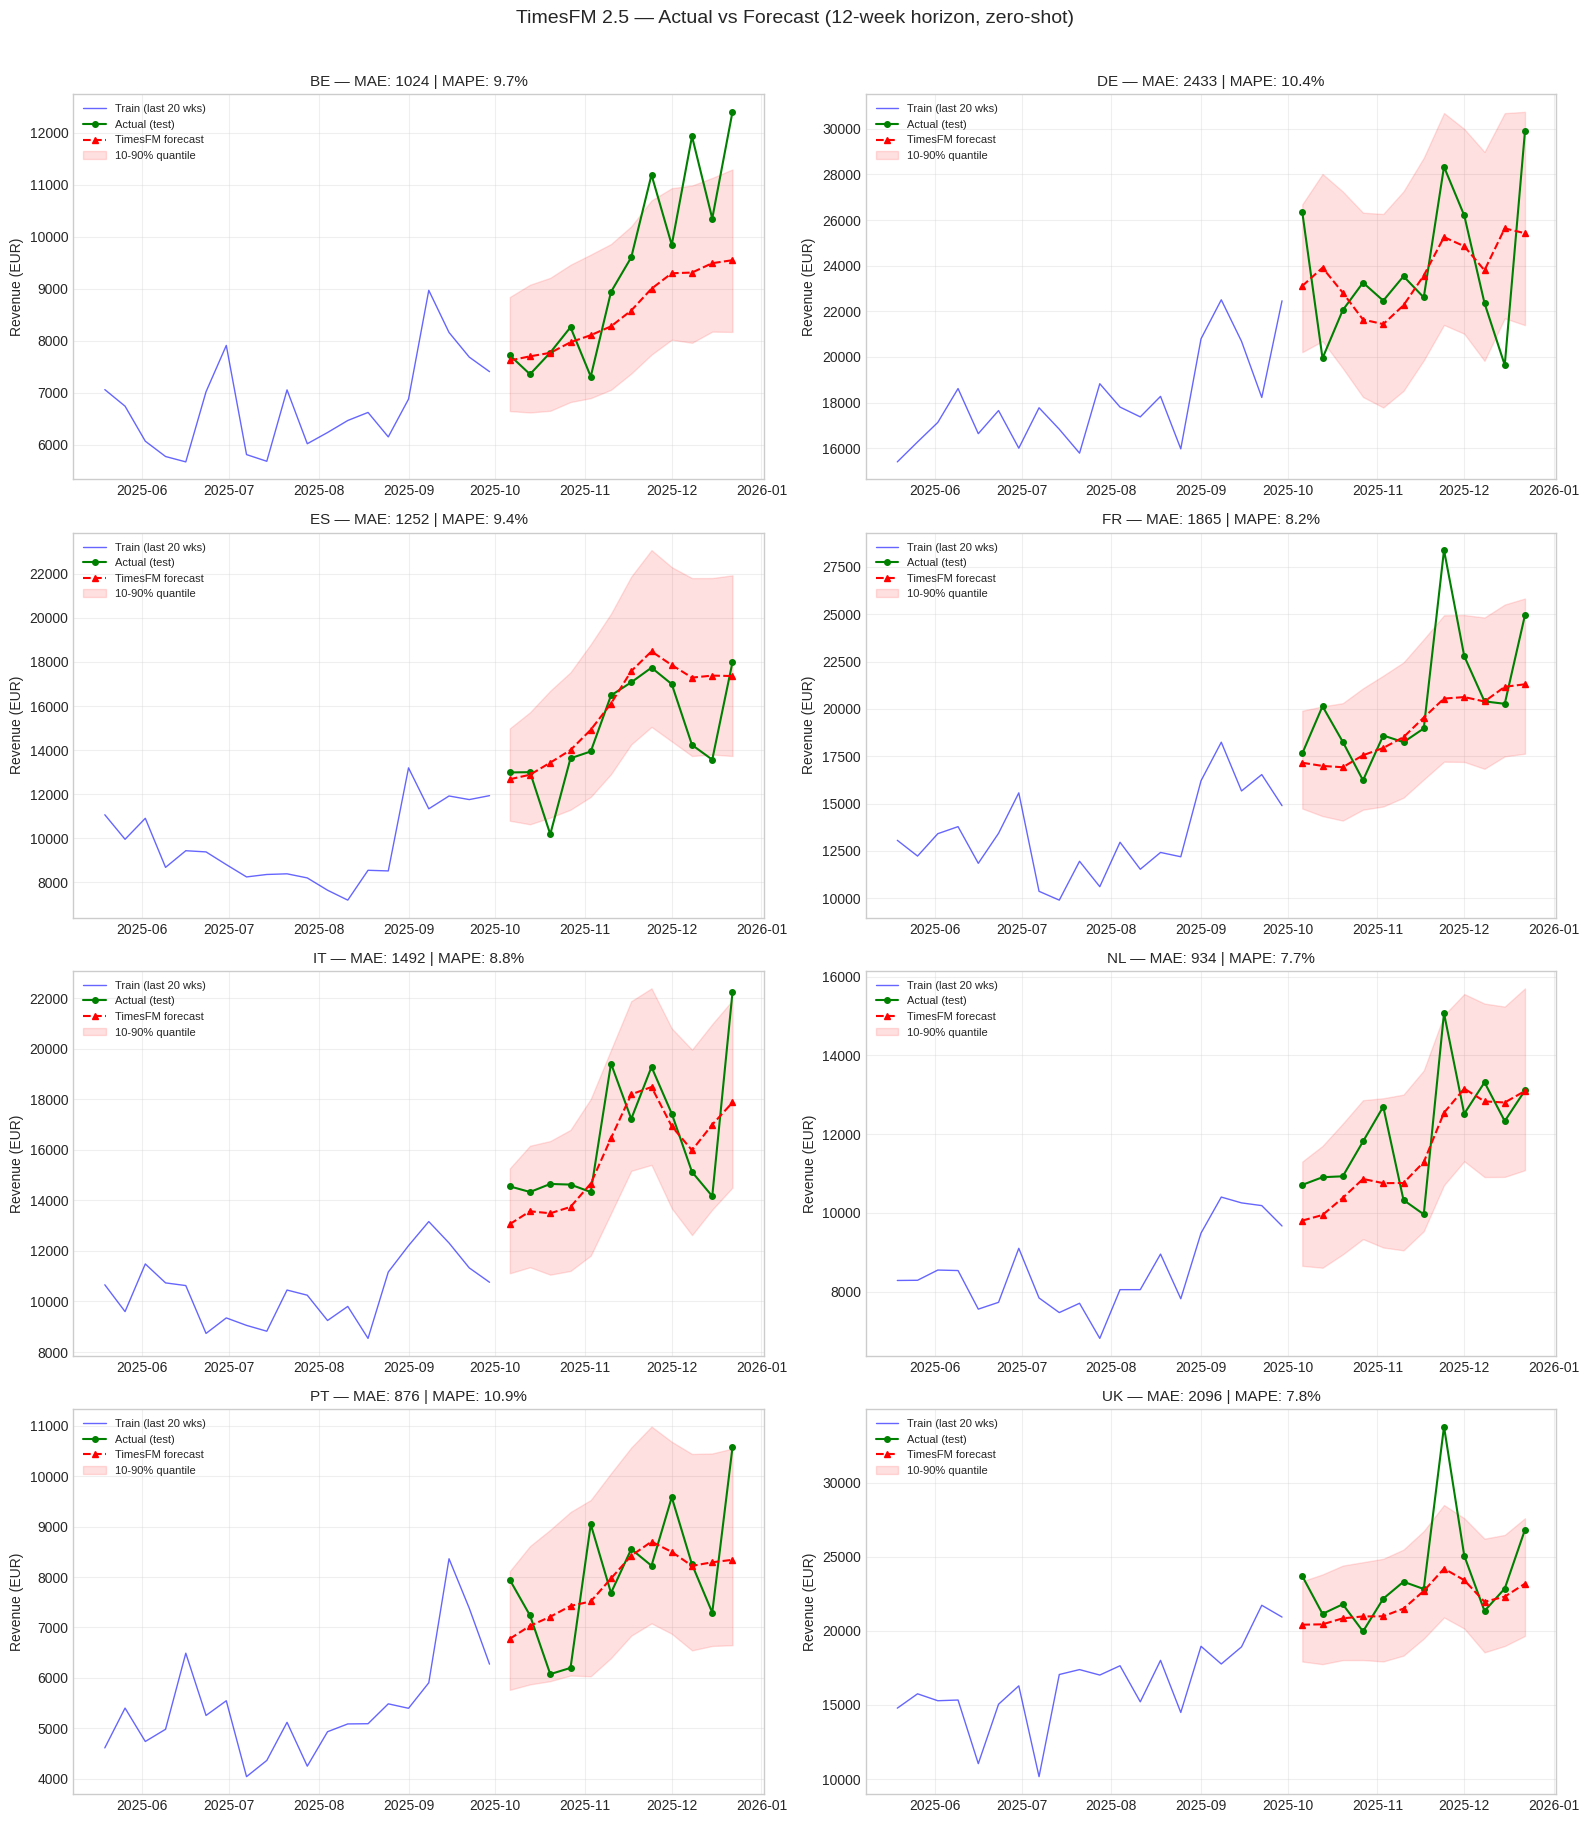

Forecast plot saved.


In [9]:
# Cell 8: Actual vs Predicted per country
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]
    test_dates = pd.to_datetime(timesfm_dates[country])
    actual = timesfm_actuals[country]
    predicted = timesfm_predictions[country]

    # Show last 20 training points for context
    country_df = sales_df[sales_df.country == country].sort_values('week_start_date')
    train_tail = country_df.iloc[-(FORECAST_HORIZON+20):-FORECAST_HORIZON]

    ax.plot(train_tail['week_start_date'], train_tail['total_revenue_eur'],
            'b-', linewidth=1, alpha=0.6, label='Train (last 20 wks)')
    ax.plot(test_dates, actual,
            'g-o', linewidth=1.5, markersize=4, label='Actual (test)')
    ax.plot(test_dates, predicted,
            'r--^', linewidth=1.5, markersize=4, label='TimesFM forecast')

    # Quantile bands if available
    if country in timesfm_quantiles:
        q = timesfm_quantiles[country]
        # quantile shape: (horizon, num_quantiles) — 10th and 90th percentile
        if q.shape[1] >= 10:
            ax.fill_between(test_dates, q[:, 1], q[:, -1],
                            alpha=0.12, color='red', label='10-90% quantile')

    mae = country_metrics[country]['mae']
    mape = country_metrics[country]['mape']
    ax.set_title(f'{country} — MAE: {mae:.0f} | MAPE: {mape:.1f}%', fontsize=11)
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('TimesFM 2.5 — Actual vs Forecast (12-week horizon, zero-shot)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/timesfm_forecast_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Forecast plot saved.')

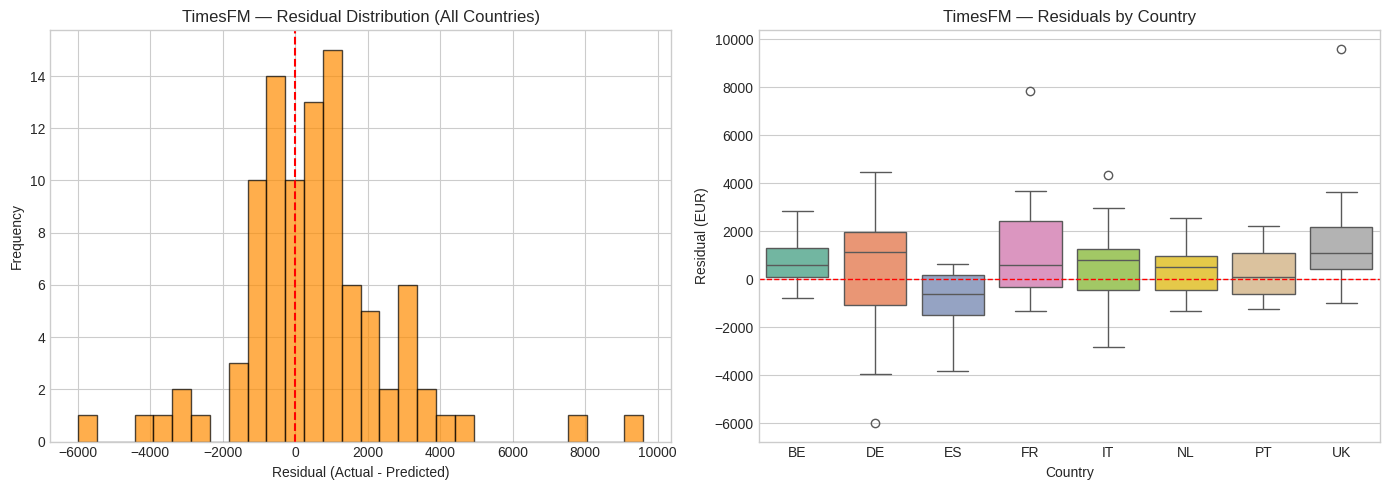

Residual analysis saved.


In [10]:
# Cell 9: Residual analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = np.array(all_actuals) - np.array(all_preds)

# Histogram
axes[0].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='darkorange')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('TimesFM — Residual Distribution (All Countries)')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Frequency')

# Residuals by country
residual_data = []
for country in countries:
    actual = timesfm_actuals[country]
    predicted = timesfm_predictions[country]
    for r in (np.array(actual) - np.array(predicted)):
        residual_data.append({'country': country, 'residual': float(r)})

res_df = pd.DataFrame(residual_data)
sns.boxplot(data=res_df, x='country', y='residual', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('TimesFM — Residuals by Country')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Residual (EUR)')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/timesfm_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Residual analysis saved.')

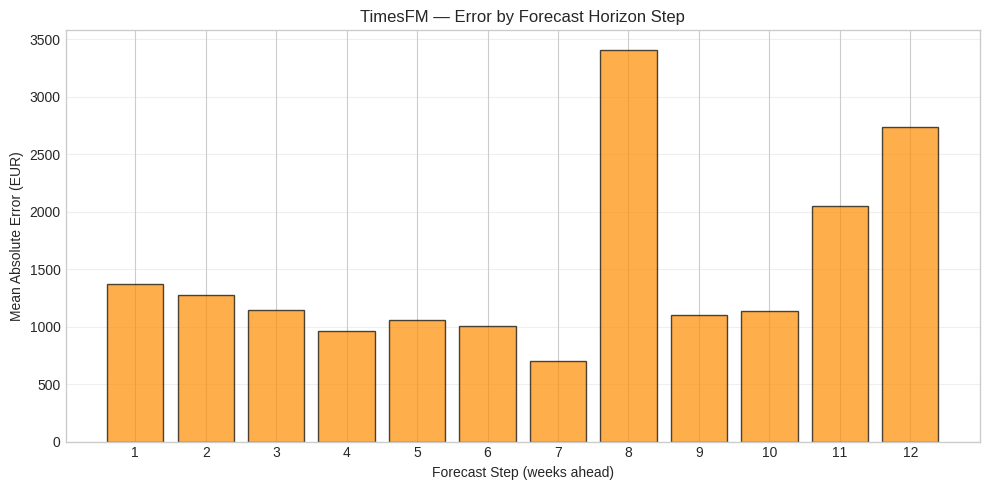

Horizon error plot saved.


In [11]:
# Cell 10: Error by forecast horizon step
fig, ax = plt.subplots(figsize=(10, 5))

step_errors = np.zeros(FORECAST_HORIZON)
for country in countries:
    actual = np.array(timesfm_actuals[country], dtype=float)
    predicted = np.array(timesfm_predictions[country], dtype=float)
    step_errors += np.abs(actual - predicted) / len(countries)

ax.bar(range(1, FORECAST_HORIZON + 1), step_errors, color='darkorange', alpha=0.7,
       edgecolor='black')
ax.set_xlabel('Forecast Step (weeks ahead)')
ax.set_ylabel('Mean Absolute Error (EUR)')
ax.set_title('TimesFM — Error by Forecast Horizon Step')
ax.set_xticks(range(1, FORECAST_HORIZON + 1))
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/timesfm_horizon_error.png', dpi=150, bbox_inches='tight')
plt.show()
print('Horizon error plot saved.')

## Exporting results

Saving metrics and forecasts to JSON for the comparison in Notebook 03.


In [12]:
# Cell 11: Save results to JSON
results = {
    'model_name': 'TimesFM',
    'framework': 'Google TimesFM 2.5 (PyTorch)',
    'model_id': 'google/timesfm-2.5-200m-pytorch',
    'timestamp': datetime.now().isoformat(),
    'configuration': {
        'approach': 'zero-shot',
        'horizon_len': FORECAST_HORIZON,
        'max_context': 1024,
        'normalize_inputs': True,
        'use_continuous_quantile_head': True,
        'fine_tuning': False,
        'regressors_used': False,
        'notes': 'Pure zero-shot — no regressors, no fine-tuning',
    },
    'dataset': {
        'total_records': len(sales_df),
        'countries': countries,
        'date_range': f"{sales_df.week_start_date.min().date()} to "
                      f"{sales_df.week_start_date.max().date()}",
        'test_size_per_country': FORECAST_HORIZON,
    },
    'metrics': {
        'overall': {k: round(float(v), 4) for k, v in overall.items()},
        'per_country': {c: {k: round(float(v), 4) for k, v in m.items()}
                        for c, m in country_metrics.items()},
    },
    'training': {
        'total_time_seconds': round(total_inference_time, 2),
        'per_country_seconds': {
            c: round(total_inference_time / len(countries), 2)
            for c in countries
        },
        'notes': 'Inference only — no training (zero-shot)',
    },
    'forecasts': {
        country: {
            'dates': [str(pd.Timestamp(d).date()) for d in timesfm_dates[country]],
            'actual': [float(v) for v in timesfm_actuals[country]],
            'predicted': [float(v) for v in timesfm_predictions[country]],
        }
        for country in countries
    },
}

# Save
results_path = f'{RESULTS_DIR}/timesfm_results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {results_path}')
print(f'\n=== TIMESFM SUMMARY ===')
print(f'Overall MAE:   {overall["mae"]:.2f} EUR')
print(f'Overall RMSE:  {overall["rmse"]:.2f} EUR')
print(f'Overall MAPE:  {overall["mape"]:.2f}%')
print(f'Overall SMAPE: {overall["smape"]:.2f}%')
print(f'Inference time: {total_inference_time:.2f}s (zero-shot, no training)')

Results saved to /content/drive/MyDrive/ML_Prediction_Analysis/TimesFM_Results/timesfm_results.json

=== TIMESFM SUMMARY ===
Overall MAE:   1496.45 EUR
Overall RMSE:  2185.28 EUR
Overall MAPE:  9.11%
Overall SMAPE: 9.29%
Inference time: 2.64s (zero-shot, no training)


---

## Wrapping up

| Aspect | Detail |
|--------|--------|
| Model | Google TimesFM 2.5 (200M params) |
| Approach | Zero-shot (no fine-tuning) |
| Architecture | Decoder-only Transformer with patching |
| Pre-training | 400B+ real-world time points |
| Context length | Up to 16k time steps |
| Quantile head | Continuous (10th-90th percentile) |
| Regressors | None (pure time-series context) |
| Forecast horizon | 12 weeks |
| Hardware | GPU recommended |

What stood out:
1. No training step at all — it leans entirely on temporal patterns learned during pre-training.
2. Unlike Prophet, there's no way to feed it external regressors like promotions or the COVID flag.
3. Its strength is generalizing from a massive pre-training corpus rather than learning anything specific to these 8 markets.
4. Batch inference is fast — all 8 countries forecast in a single call.
5. The quantile head gives uncertainty estimates without needing MCMC sampling.

**Trade-offs vs. Prophet:** no configuration or tuning needed, and uncertainty comes built in — but it can't use known external factors like promotions or holidays. Notebook 03 will put a number on exactly how much that trade-off costs.

Next: the head-to-head comparison with Prophet in Notebook 03.
